# Notebook 02: Rotations
## From 2D angs to quaternion kinematics

Rotations are where rigid body dynamics get interesting and where most people's intuition breaks. In 2D, a rotation is just an angle. In 3D, it's a minefield of conventions, singularities, and gotchas. 

We'll build up from 2D rotations (trivial) to Euler angles (intuitive but broken) to quaternions (weird but correct), and end with the kinematic equation that bridges rotation representation to dynamics. 

**Roadmap:**
1. 2D rotations: warm up, everything commutes
2. 3D Euler angles: intuitive but non-commutative
3. Gimbal lock: why euler angles break
4. Quaternions: the fix
5. Euler <-> Quaternion conversion and where it fails
6. SLERP: smooth interpolation
7. Quaternion kinematics: the bridge to dynamics

In [18]:
%matplotlib inline

import sys
sys.path.insert(0, ".")

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML

from utils import (
    make_rocket_body, euler_to_rotation_matrix, rot_z, draw_body_3d, draw_axes_3d, set_equal_3d_axes, 
    quat_from_axis_angle, quat_from_euler, quat_to_euler,
    quat_to_rotation_matrix, quat_rotate_vector, quat_multiply, quat_conjugate, quat_normalize, quat_derivative, slerp
)
from plotting import C_BODY, C_GHOST, C_ACCENT, C_ACCENT2, C_GREEN, setup_style

setup_style()
plt.rcParams.update({'font.size': 11})

---
## 1. Rotations in 2D

Where does the rotation matrix come from?
- Start with a point $\mathbf{p} = (x, y)$. In polar form: $x = r\cos\alpha$, $y = r\sin\alpha$.
- Rotate it by angle $\theta$ around the origin. 
- The new point is at angle $\alpha + \theta$, same radius:

$$x' = r\cos(\alpha + \theta) = r\cos\alpha\cos\theta - r\sin\alpha\sin\theta = x\cos\theta - y\sin\theta$$
$$y' = r\sin(\alpha + \theta) = r\sin\alpha\cos\theta + r\cos\alpha\sin\theta = y\cos\theta + x\sin\theta$$

Stacking these into a matrix equation and we get $\mathbf{p}' = R(\theta)\,\mathbf{p}$:

$$R(\theta) = \begin{bmatrix} \cos\theta & -\sin\theta \\ \sin\theta & \cos\theta \end{bmatrix}$$

The matrix entries are just the trig addition formulas packaged into linear algebra. Why a matrix and not just "add $\theta$"? Because matrices rotate _vectors_, not just angles. A shape is a collection of points - multiply each by $R$ and the whole shape rotates rigidly. And matrices compose: $R(\alpha)\,R(\beta) = R(\alpha + \beta)$, which is exactly, "two rotations in sequence = one rotation by the sum."

Properties:
- $R^T R = I$ (orthogonal)
- $\det(R) = 1$ (proper rotation, no reflection)
- Composing rotations: $R(\alpha) R(\beta) = R(\alpha + \beta)$

The critical property for 2D: **rotations commute**. $R(\alpha) R(\beta) = R(\beta) R(\alpha)$. This will not hold in 3D.

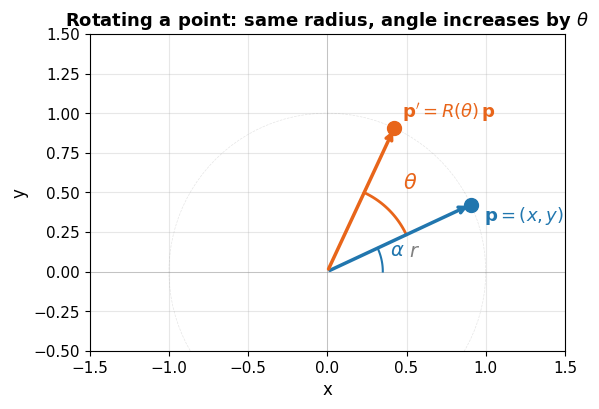

In [2]:
# Visualize the derivation: a point p rotated by theta

fig, ax = plt.subplots(figsize=(6, 6))
ax.set_xlim(-1.5, 1.5)
ax.set_ylim(-0.5, 1.5)
ax.set_aspect('equal')
ax.axhline(0, color='gray', linewidth=0.5, alpha=0.5)
ax.axvline(0, color='gray', linewidth=0.5, alpha=0.5)

r = 1.0
alpha = np.radians(25)  # original angle
theta = np.radians(40)  # rotation angle

# Original point
px, py = r * np.cos(alpha), r * np.sin(alpha)
# Rotated point
px2, py2 = r * np.cos(alpha + theta), r * np.sin(alpha + theta)

# Draw the arc (radius)
arc_angles = np.linspace(0, 2*np.pi, 100)
ax.plot(r * np.cos(arc_angles), r * np.sin(arc_angles), color='gray', linewidth=0.5, alpha=0.2, linestyle='--')

# Draw vectors from origin to each point
ax.annotate('', xy=(px, py), xytext=(0, 0), arrowprops=dict(arrowstyle='->', color='#2176AE', lw=2.5))
ax.annotate('', xy=(px2, py2), xytext=(0, 0), arrowprops=dict(arrowstyle='->', color='#E8651A', lw=2.5))

# Label points
ax.plot(px, py, 'o', color='#2176AE', markersize=10, zorder=5)
ax.plot(px2, py2, 'o', color='#E8651A', markersize=10, zorder=5)
ax.text(px + 0.08, py - 0.1, r'$\mathbf{p} = (x, y)$', fontsize=13, color='#2176AE', fontweight='bold')
ax.text(px2 + 0.05, py2 + 0.07, r'$\mathbf{p}^\prime = R(\theta)\,\mathbf{p}$', fontsize=13, color='#E8651A', fontweight='bold')

# Draw angle alpha (from x-axis to p)
arc_a = np.linspace(0, alpha, 30)
ar = 0.35
ax.plot(ar * np.cos(arc_a), ar * np.sin(arc_a), color='#2176AE', linewidth=1.5)
ax.text(ar * 1.3 * np.cos(alpha/2), ar * 1.3 * np.sin(alpha/2), r'$\alpha$', fontsize=14, color='#2176AE', ha='center')

# Draw angle theta (from p to p')
arc_t = np.linspace(alpha, alpha + theta, 30)
ar2 = 0.55
ax.plot(ar2 * np.cos(arc_t), ar2 * np.sin(arc_t), color='#E8651A', linewidth=2)
ax.text(ar2 * 1.35 * np.cos(alpha + theta/2), ar2 * 1.35 * np.sin(alpha + theta/2), r'$\theta$', fontsize=15, color='#E8651A', ha='center', fontweight='bold')

# Label radius
mid_r = 0.5 * np.array([np.cos(alpha - 0.08), np.sin(alpha - 0.08)])
ax.text(mid_r[0] + 0.05, mid_r[1] - 0.08, r'$r$', fontsize=14, color='gray', style='italic')

ax.set_xlabel('x', fontsize=12)
ax.set_ylabel('y', fontsize=12)
ax.set_title('Rotating a point: same radius, angle increases by $\\theta$', fontsize=13, fontweight='bold')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

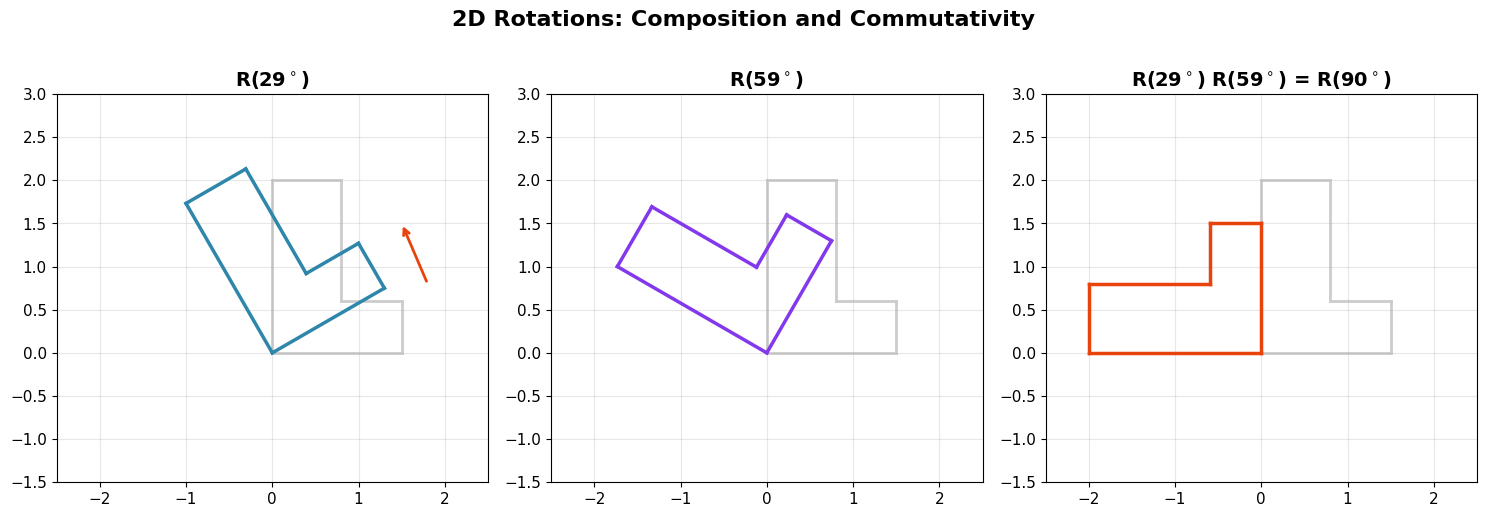

In [3]:
def rot2d(theta):
    """2D rotation matrix."""
    c, s = np.cos(theta), np.sin(theta)
    return np.array([[c, -s], [s, c]])

# Define an L-shape as a set of points
L_shape = np.array([
    [0, 0], [0, 2], [0, 2], [0.8, 2],  # vertical bar top
    [0, 0], [1.5, 0], [1.5, 0], [1.5, 0.6],  # horizontal bar
    [1.5, 0.6], [0.8, 0.6], [0.8, 0.6], [0.8, 2],   # inner corner
    [0, 0], [0, 0],  # origin marker
]).T  # shape (2, N)

# Apply rotations
theta1 = np.radians(30)
theta2 = np.radians(60)

L_rot1 = rot2d(theta1) @ L_shape
L_rot2 = rot2d(theta2) @ L_shape
L_composed = rot2d(theta1 + theta2) @ L_shape

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax in axes:
    ax.set_aspect('equal')
    ax.set_xlim(-2.5, 2.5)
    ax.set_ylim(-1.5, 3)
    # Draw the original L as ghost
    for i in range(0, L_shape.shape[1], 2):
        ax.plot(L_shape[0, i:i+2], L_shape[1, i:i+2], color=C_GHOST, lw=2, zorder=1)

# Panel 1: Rotate by 30 deg
for i in range(0, L_rot1.shape[1], 2):
    axes[0].plot(L_rot1[0, i:i+2], L_rot1[1, i:i+2], color=C_BODY, lw=2.5, zorder=2)
axes[0].set_title(f"R({int(np.degrees(theta1))}$^\\circ$)", fontsize=14, fontweight='bold')
axes[0].annotate("", xy=(1.5, 1.5), xytext=(1.8, 0.8), arrowprops=dict(arrowstyle='->', color=C_ACCENT, lw=2))

# Panel 2: Rotate by 60 deg
for i in range(0, L_rot2.shape[1], 2):
    axes[1].plot(L_rot2[0, i:i+2], L_rot2[1, i:i+2], color=C_ACCENT2, lw=2.5, zorder=2)
axes[1].set_title(f"R({int(np.degrees(theta2))}$^\\circ$)", fontsize=14, fontweight='bold')

# Panel 3: Composed rotation = R(30+60) = R(90)
for i in range(0, L_composed.shape[1], 2):
    axes[2].plot(L_composed[0, i:i+2], L_composed[1, i:i+2], color=C_ACCENT, lw=2.5, zorder=2)
axes[2].set_title(f"R({int(np.degrees(theta1))}$^\\circ$) R({int(np.degrees(theta2))}$^\\circ$) = R({int(np.degrees(theta1 + theta2))}$^\\circ$)", fontsize=14, fontweight='bold')

fig.suptitle("2D Rotations: Composition and Commutativity", fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [4]:
# Verify commutativity of rotations in 2D
a, b = np.radians(37), np.radians(73)
R_ab = rot2d(a) @ rot2d(b)
R_ba = rot2d(b) @ rot2d(a)

print('2D Rotations COMMUTE:')
print(f'    R({37})R({73}) = \n{R_ab}')
print(f'    R({73})R({37}) = \n{R_ba}')
print(f'    Difference (Frobenius norm) = {np.linalg.norm(R_ab - R_ba):.2e}')
print()
print('This is because R(a)R(b) = R(a+b) = R(b+a) = R(b)R(a).')
print('Enjoy it while it lasts; 3D is not so kind.')

2D Rotations COMMUTE:
    R(37)R(73) = 
[[-0.34202014 -0.93969262]
 [ 0.93969262 -0.34202014]]
    R(73)R(37) = 
[[-0.34202014 -0.93969262]
 [ 0.93969262 -0.34202014]]
    Difference (Frobenius norm) = 0.00e+00

This is because R(a)R(b) = R(a+b) = R(b+a) = R(b)R(a).
Enjoy it while it lasts; 3D is not so kind.


### Body Frame vs World Frame

Before we get into rotations, a critical distinction. There are two coordinate systems at play:

- **World frame:** fixed to the ground. World Z points up (altitude), XY is the ground plane. This never moves.
- **Body frame:** bolted to the rocket. Body X always points along the nose, body Y points out to the side, body Z completes the right-hand rule. This frame rotates _with_ the rocket.

When the rocket stands upright on the launchpad, body X (nose) happens to align with world Z (up). But as the rocket tilts, body X follows the nose while world Z stays fixed.

Roll, pitch, and yaw form a **nested chain**, and each one turns about the axis of a _different_ frame:

| Angle | Turns about | Place in the chain |
|---|---|---|
| **Yaw** $\psi = R_z$ | **world** Z, the fixed vertical | outermost |
| **Pitch** $\theta = R_y$ | the Y axis of the frame left behind by yaw (horizontal) | middle |
| **Roll** $\phi = R_x$ | **body** X, the nose-to-tail axis | innermost |

Only roll turns about a body axis. Only yaw turns about a world axis. Pitch turns about something in between: always horizontal, but pointing in whatever compass direction yaw left it.

Picture a physical gimbal. The outer ring is bolted to the ground and spins about the vertical (yaw). The middle ring hangs inside the outer one (pitch). The rocket hangs inside the middle ring, free to spin about its own nose (roll). Each ring carries everything nested inside it: yaw moves the pitch and roll axes, pitch moves the roll axis, roll moves only the rocket.

The shorthand "pitch tilts the nose up/down, yaw swings the nose left/right" describes these angles well when the rocket is near level ($\theta \approx 0$), where body Z happens to line up with world Z. Steeply pitched, the shorthand no longer tracks the axes and the table above is what holds.

The figure below shows the same rocket in two orientations - the body axes (RGB = XYZ) move with the rocket, while the world axes stay fixed.


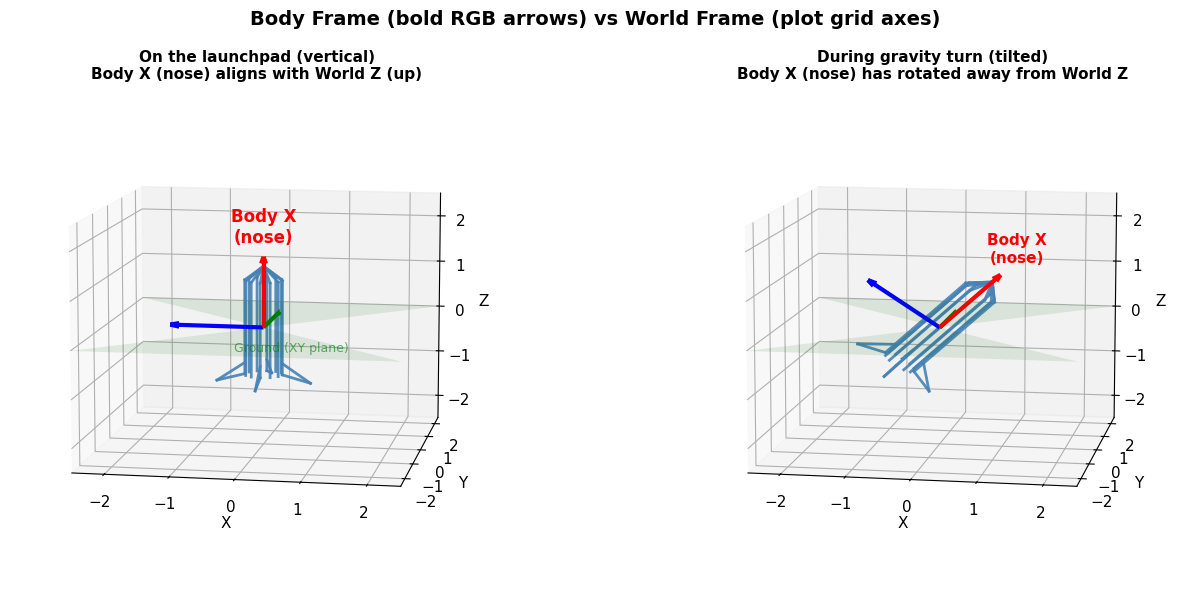

Bold RGB arrows = body frame axes (rotate with the rocket)
Plot grid (X, Y, Z labels) = world frame axes (fixed to ground)
Green surface = ground (world XY plane)
World Z = up. Body X = always along the nose.


In [5]:
# Body frame vs world frame: same rocket, two orientations
fig = plt.figure(figsize=(14, 6))

rocket_demo = make_rocket_body(length=2.0, radius=0.3)

# Left: rocket vertical (as on launchpad): body X aligns with world Z
ax1 = fig.add_subplot(121, projection='3d')
R_vertical = euler_to_rotation_matrix(roll=0, pitch=-np.pi/2, yaw=0)  # body X -> world Z (nose up)
draw_body_3d(ax1, rocket_demo, R_vertical, color='steelblue', alpha=0.9, linewidth=2.0)
draw_axes_3d(ax1, R_vertical, length=1.5, linewidth=3.0)

# Label the nose
nose_world = R_vertical @ np.array([1.6, 0, 0])
ax1.text(nose_world[0], nose_world[1], nose_world[2] + 0.2, 'Body X\n(nose)', fontsize=12, color='red', fontweight='bold', ha='center')

# Draw a ground plane at Z=0
ground = 2.5
gx = np.array([-ground, ground, ground, -ground])
gy = np.array([-ground, -ground, ground, ground])
gz = np.zeros(4)
ax1.plot_surface(gx.reshape(2,2), gy.reshape(2,2), gz.reshape(2,2), alpha=0.1, color='green')
ax1.text(0, -ground, 0.1, 'Ground (XY plane)', fontsize=9, color='green', alpha=0.6)

set_equal_3d_axes(ax1, radius=2.5)
ax1.set_title('On the launchpad (vertical)\nBody X (nose) aligns with World Z (up)', fontsize=11, fontweight='bold')
ax1.view_init(elev=10, azim=-80)

# Right: rocket tilted - body X no longer aligns with world Z
ax2 = fig.add_subplot(122, projection='3d')
R_tilted = euler_to_rotation_matrix(roll=0, pitch=np.radians(-50), yaw=0)
draw_body_3d(ax2, rocket_demo, R_tilted, color='steelblue', alpha=0.9, linewidth=2.0)
draw_axes_3d(ax2, R_tilted, length=1.5, linewidth=3.0)

nose_world2 = R_tilted @ np.array([1.6, 0, 0])
ax2.text(nose_world2[0] + 0.2, nose_world2[1], nose_world2[2] + 0.2, 'Body X\n(nose)', fontsize=11, color='red', fontweight='bold', ha='center')
ax2.plot_surface(gx.reshape(2,2), gy.reshape(2,2), gz.reshape(2,2), alpha=0.1, color='green')
set_equal_3d_axes(ax2, radius=2.5)
ax2.set_title('During gravity turn (tilted)\nBody X (nose) has rotated away from World Z', fontsize=11, fontweight='bold')
ax2.view_init(elev=10, azim=-80)

fig.suptitle('Body Frame (bold RGB arrows) vs World Frame (plot grid axes)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print('Bold RGB arrows = body frame axes (rotate with the rocket)')
print('Plot grid (X, Y, Z labels) = world frame axes (fixed to ground)')
print('Green surface = ground (world XY plane)')
print('World Z = up. Body X = always along the nose.')

---
## 2. Rotations in 3D: Euler Angles

Three elementary rotation matrices, each about one axis:

$$R_x(\phi) = \begin{bmatrix} 1 & 0 & 0 \\ 0 & \cos\phi & -\sin\phi \\ 0 & \sin\phi & \cos\phi \end{bmatrix}, \quad
R_y(\theta) = \begin{bmatrix} \cos\theta & 0 & \sin\theta \\ 0 & 1 & 0 \\ -\sin\theta & 0 & \cos\theta \end{bmatrix}, \quad
R_z(\psi) = \begin{bmatrix} \cos\psi & -\sin\psi & 0 \\ \sin\psi & \cos\psi & 0 \\ 0 & 0 & 1 \end{bmatrix}$$

**ZYX (aerospace) convention:** $R = R_z(\text{yaw}) \cdot R_y(\text{pitch}) \cdot R_x(\text{roll})$

This single product has two equivalent readings:

- **Fixed-axis (extrinsic), right to left:** roll about **world** X, then pitch about **world** Y, then yaw about **world** Z. Three turns about three axes that never move.
- **Body-axis (intrinsic), left to right:** yaw about **body** Z, then pitch about the **new** body Y, then roll about the **new** body X. Each turn is taken about an axis the previous turns have already moved.

Both give the same matrix, and both put **yaw on the outside and roll on the inside**: the gimbal chain from the previous section.

**Axis convention note:** Our rocket points along **body X**, matching standard aerospace convention, and
- Roll = $R_x$ (spin about the nose-to-tail axis)
- Pitch = $R_y$ (about a horizontal axis; near level, this tilts the nose up/down)
- Yaw = $R_z$ (about the world vertical; near level, this swings the nose left/right)


In [6]:
# Animate roll, pitch, yaw from 0 to 45 degrees
# Start from the launchpad orientation (nose up along world Z)
# then apply each Euler rotation on top.
rocket = make_rocket_body(length=2.0, radius=0.25)
max_angle = np.radians(45)
n_anim_frames = 60

# Base orientation: pitch -90 to put nose along world Z (launchpad)
R_launchpad = euler_to_rotation_matrix(roll=0, pitch=-np.pi/2, yaw=0)

fig = plt.figure(figsize=(15, 5.5))
ax_roll = fig.add_subplot(131, projection='3d')
ax_pitch = fig.add_subplot(132, projection='3d')
ax_yaw = fig.add_subplot(133, projection='3d')

def update_euler_anim(frame):
    angle = max_angle * frame / n_anim_frames
    deg = np.degrees(angle)

    configs = [
        (ax_roll, euler_to_rotation_matrix(roll=angle, pitch=0, yaw=0), f'Roll = {deg:.0f}\u00b0\n(spin about nose axis)', (5, -80)), 
        (ax_pitch, euler_to_rotation_matrix(roll=0, pitch=angle, yaw=0), f'Pitch = {deg:.0f}\u00b0\n(nose tilts up/down)', (10, -80)),
        (ax_yaw, euler_to_rotation_matrix(roll=0, pitch=0, yaw=angle), f'Yaw = {deg:.0f}\u00b0\n(nose swings left/right)', (60, -80))
    ]

    for ax, R_euler, title, view in configs:
        ax.cla()
        # Total rotation = Euler rotation applied AFTER launchpad orientation
        R_total =  R_launchpad @ R_euler
        # Ghost of the launchpad orientation (no Euler rotation)
        draw_body_3d(ax, rocket, R_launchpad, color='lightgray', alpha=0.2)
        # Rotated rocket
        draw_body_3d(ax, rocket, R_total, color='steelblue', alpha=0.9)
        draw_axes_3d(ax, R_total, length=1.0)
        set_equal_3d_axes(ax, radius=1.8)
        ax.set_title(title, fontsize=11, fontweight='bold')
        ax.view_init(elev=view[0], azim=view[1])

    return []

fig.suptitle('Euler Angle Rotations (ZYX Convention) - starting from vertical', fontsize=14, fontweight='bold')
anim_euler = animation.FuncAnimation(fig, update_euler_anim, frames=n_anim_frames + 1, interval=50, blit=False)
plt.close(fig)
HTML(anim_euler.to_html5_video())

### 3D rotations do NOT commute

Unlike 2D, the order matters. $R_y(\theta) R_z(\psi) \neq R_z(\psi) R_y(\theta)$ in general. 

Pitch-then-yaw gives a different final orientation than yaw-then-pitch. Let's see it. 

In [7]:
# Animate non-commutativity: pitch-then-yaw vs yaw-then-pitch
# State from launchpad (vertical), apply rotations in body frame
n_frames_nc = 60
angle_max = np.radians(60)

R_launchpad_nc = euler_to_rotation_matrix(roll=0, pitch=-np.pi/2, yaw=0)

fig_nc = plt.figure(figsize=(14, 6))
ax_py = fig_nc.add_subplot(121, projection='3d')
ax_yp = fig_nc.add_subplot(122, projection='3d')

def update_noncommute(frame):
    half = n_frames_nc // 2

    if frame <= half:
        t = frame / half
        # Left: pitch first (body frame)
        R_left = R_launchpad_nc @ euler_to_rotation_matrix(roll=0, pitch=angle_max * t, yaw=0)
        title_left = f'Step 1: Pitch {np.degrees(angle_max * t):.0f}\u00b0'
        # Right: yaw first (body frame)
        R_right = R_launchpad_nc @ euler_to_rotation_matrix(roll=0, pitch=0, yaw=angle_max * t)
        title_right = f'Step 1: Yaw {np.degrees(angle_max * t):.0f}\u00b0'
    else:
        t = (frame - half) / half
        # Left: pitch done, now yaw
        R_left = R_launchpad_nc @ euler_to_rotation_matrix(roll=0, pitch=angle_max, yaw=angle_max * t)
        title_left = f'Step 2: Yaw {np.degrees(angle_max * t):.0f}\u00b0'
        # Right: yaw done, now pitch
        R_right = R_launchpad_nc @ euler_to_rotation_matrix(roll=0, pitch=angle_max * t, yaw=angle_max)
        title_right = f'Step 2: Pitch {np.degrees(angle_max * t):.0f}\u00b0'

    for ax, R, title in [(ax_py, R_left, title_left), (ax_yp, R_right, title_right)]:
        ax.cla()
        draw_body_3d(ax, rocket, R_launchpad_nc, color='lightgray', alpha=0.15)
        draw_body_3d(ax, rocket, R, color='steelblue', alpha=0.9)
        draw_axes_3d(ax, R, length=1.0)
        set_equal_3d_axes(ax, radius=1.8)
        ax.set_title(title, fontsize=12, fontweight='bold')
        ax.view_init(elev=20, azim=-80)

    ax_py.text2D(0.5, 0.02, 'Pitch then Yaw', transform=ax_py.transAxes, ha='center', fontsize=11, color='steelblue')
    ax_yp.text2D(0.5, 0.02, 'Yaw then Pitch', transform=ax_yp.transAxes, ha='center', fontsize=11, color='steelblue')

    fig_nc.suptitle('3D Rotations Do NOT Commute', fontsize=14, fontweight='bold')

    return []

anim_nc = animation.FuncAnimation(fig_nc, update_noncommute, frames=n_frames_nc + 1, interval=60, blit=False)
plt.close(fig_nc)
HTML(anim_nc.to_html5_video())
        

---
## 3. Gimbal Lock: Why Euler Angles Break

This is the single most important concept in the notebook.

**Gimbal lock** occurs when pitch $= \pm 90^\circ$: the orientation where the innermost gimbal axis (roll, along the nose) has been tipped onto the outermost gimbal axis (yaw, the world vertical). Both then turn the rocket about the same physical line.

Follow the angle between those two axes as pitch changes. Yaw always turns about world Z. Roll always turns about the nose. Pitching by $\theta$ tilts the nose away from horizontal by exactly $\theta$, so

$$\angle(\text{roll axis},\ \text{yaw axis}) = 90^\circ - |\theta|$$

At $\theta = 0$ the angle is $90^\circ$: three mutually perpendicular gimbal axes, three knobs pointing in three independent directions. At $\theta = \pm 90^\circ$ the angle is $0^\circ$: roll and yaw are the same rotation, and the three knobs reach only two independent directions. In between, the axes are partly aligned and the parameterization degrades smoothly. Gimbal lock is not a trapdoor at exactly $90^\circ$; it is a slide that gets steeper the closer you get.

Mathematically, when pitch $= \pi/2$:

$$R = R_z(\psi) \cdot R_y(\pi/2) \cdot R_x(\phi) = \begin{bmatrix} 0 & \sin(\phi-\psi) & \cos(\phi-\psi) \\ 0 & \cos(\phi-\psi) & -\sin(\phi-\psi) \\ -1 & 0 & 0 \end{bmatrix}$$

Only the **difference** $(\phi - \psi)$ = (roll $-$ yaw) survives. Changing roll by $+\delta$ has exactly the same effect as changing yaw by $-\delta$. Three parameters, two degrees of freedom.


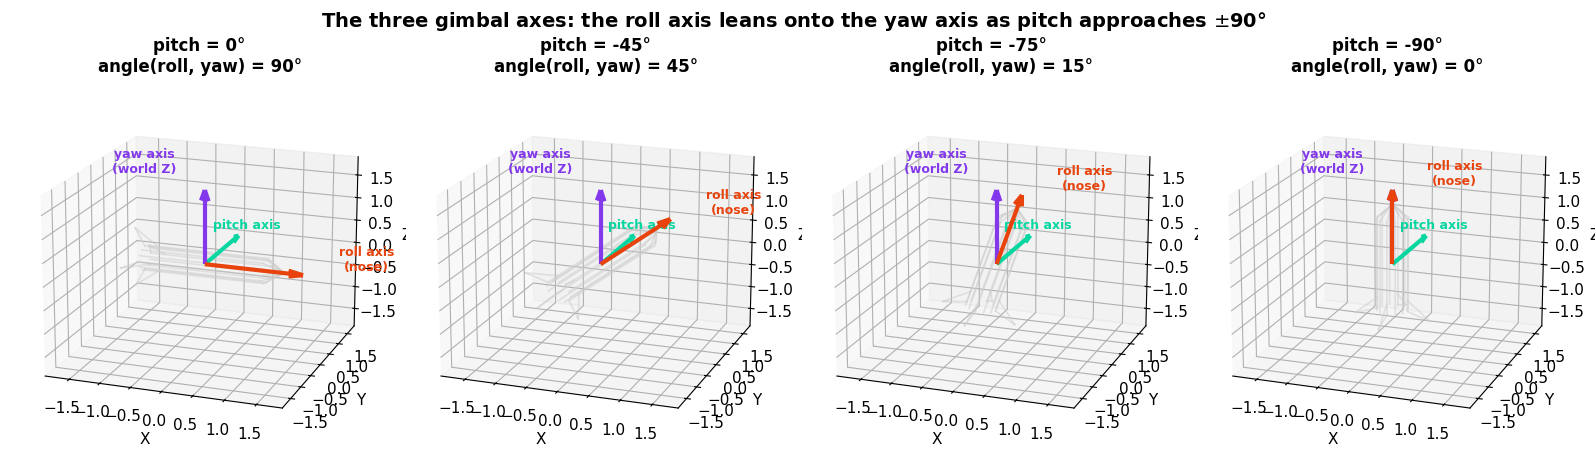

The pitch axis stays perpendicular to the other two at all times.
The roll axis and the yaw axis close from 90° down to 0° as the nose comes up.
At 0° they are the same line: rolling and yawing do the same thing.


In [8]:
# The three gimbal axes drawn in world coordinates, as pitch sweeps from level to nose-up.
# Each Euler angle turns about a different axis:
#     yaw axis   = world Z                       (fixed vertical, never moves)
#     pitch axis = world Y after yaw is applied  (horizontal; yaw = 0 here, so it is world Y)
#     roll axis  = body X, the nose              (carried around by pitch and yaw)

pitch_angles_deg = [0, -45, -75, -90]

fig = plt.figure(figsize=(16, 5))

for idx, pitch_deg in enumerate(pitch_angles_deg):
    pitch = np.radians(pitch_deg)
    R = euler_to_rotation_matrix(roll=0, pitch=pitch, yaw=0)

    yaw_axis = np.array([0.0, 0.0, 1.0])        # world Z
    pitch_axis = np.array([0.0, 1.0, 0.0])      # world Y (yaw = 0)
    roll_axis = R @ np.array([1.0, 0.0, 0.0])   # body X = the nose

    # Angle between the innermost gimbal axis (roll) and the outermost one (yaw)
    cos_angle = np.clip(np.dot(roll_axis, yaw_axis), -1.0, 1.0)
    angle_deg = np.degrees(np.arccos(cos_angle))

    ax = fig.add_subplot(1, len(pitch_angles_deg), idx + 1, projection='3d')
    draw_body_3d(ax, rocket, R, color=C_GHOST, alpha=0.5, linewidth=1.2)

    # Label offsets keep the text readable once two axes overlap at pitch = -90
    axis_specs = [
        (yaw_axis, C_ACCENT2, 'yaw axis\n(world Z)', np.array([-1.0, 0.0, 0.25])),
        (pitch_axis, C_GREEN, 'pitch axis', np.array([0.0, 0.4, 0.0])),
        (roll_axis, C_ACCENT, 'roll axis\n(nose)', np.array([1.0, 0.0, 0.25])),
    ]
    for axis, color, label, label_offset in axis_specs:
        tip = 1.6 * axis
        ax.quiver(0, 0, 0, tip[0], tip[1], tip[2], color=color, linewidth=3.0, arrow_length_ratio=0.15)
        label_pos = tip + label_offset
        ax.text(label_pos[0], label_pos[1], label_pos[2], label, color=color, fontsize=9, fontweight='bold', ha='center')

    set_equal_3d_axes(ax, radius=1.9)
    ax.set_title(f'pitch = {pitch_deg}°\nangle(roll, yaw) = {angle_deg:.0f}°', fontsize=12, fontweight='bold')
    ax.view_init(elev=18, azim=-70)

fig.suptitle('The three gimbal axes: the roll axis leans onto the yaw axis as pitch approaches $\\pm$90°',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print('The pitch axis stays perpendicular to the other two at all times.')
print('The roll axis and the yaw axis close from 90° down to 0° as the nose comes up.')
print('At 0° they are the same line: rolling and yawing do the same thing.')


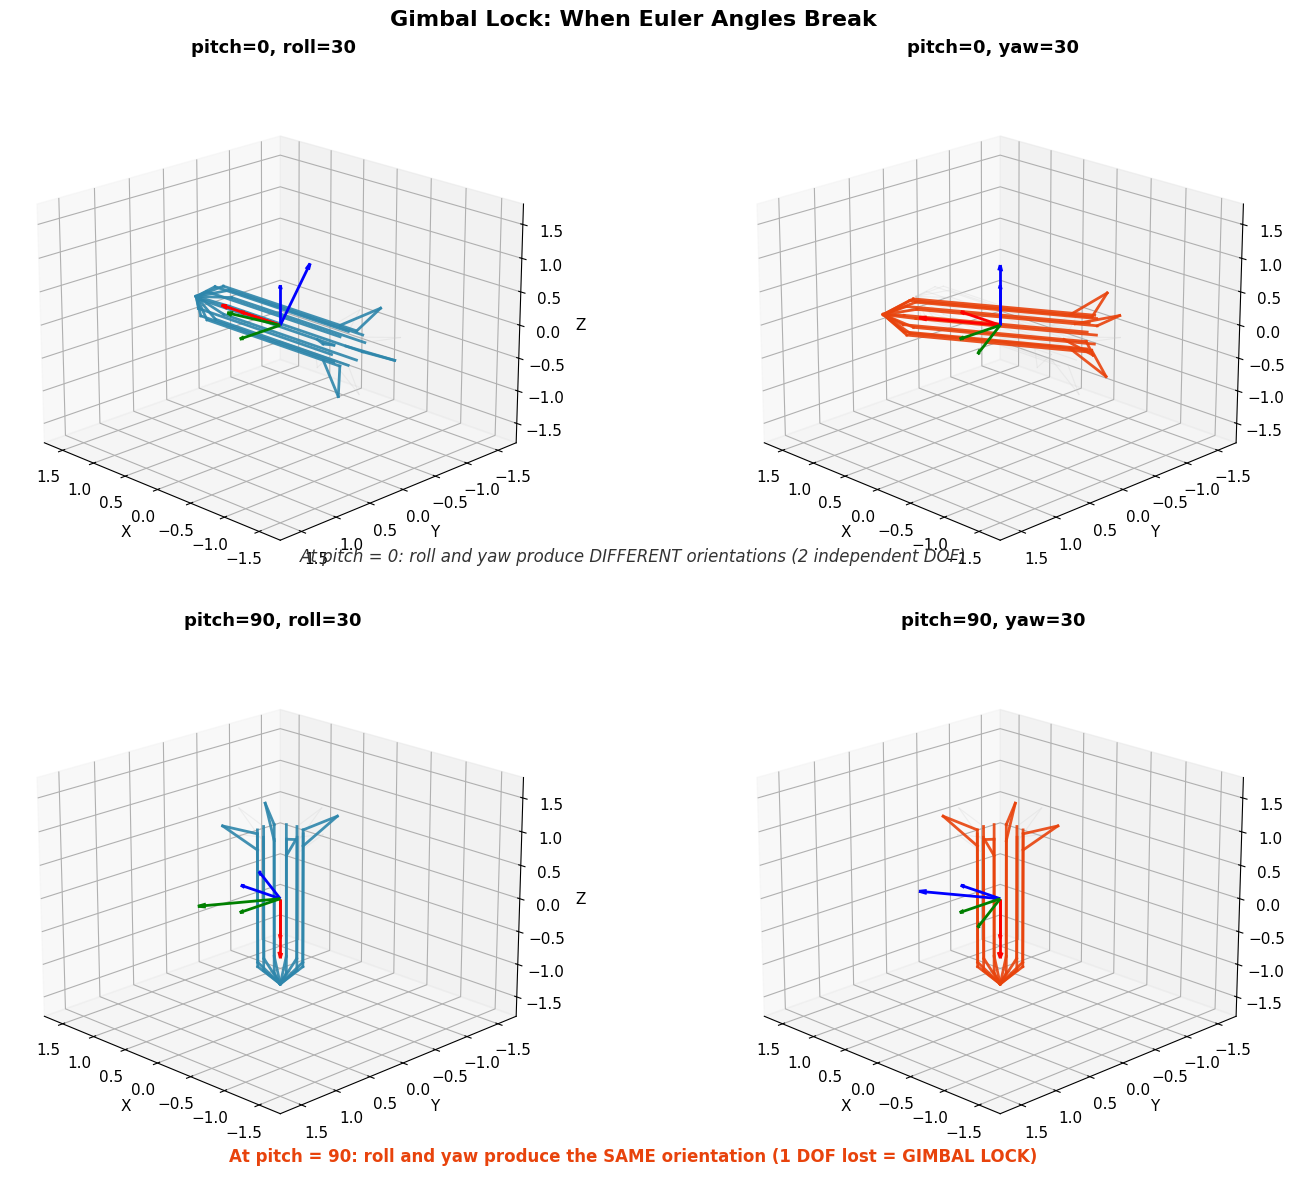

In [9]:
# THE KEY VISUAL: Gimbal lock demonstration
# Compare roll vs yaw at pitch=0 (both work) and pitch=90 (gimbal lock; indistinguishable)

small_angle = np.radians(30)  # amount of roll or yaw to apply

configs = [
    # (roll, pitch, yaw, title, color)
    (small_angle, 0, 0, "pitch=0, roll=30", C_BODY),
    (0, 0, small_angle, "pitch=0, yaw=30", C_ACCENT),
    (small_angle, np.pi/2, 0, "pitch=90, roll=30", C_BODY),
    (0, np.pi/2, small_angle, "pitch=90, yaw=30", C_ACCENT),
]

fig = plt.figure(figsize=(16, 12))

for idx, (roll, pitch, yaw, title, color) in enumerate(configs):
    ax = fig.add_subplot(2, 2, idx + 1, projection='3d')
    R = euler_to_rotation_matrix(roll=roll, pitch=pitch, yaw=yaw)

    # Reference: body at just the pitch angle (no roll or yaw)
    R_ref = euler_to_rotation_matrix(roll=0, pitch=pitch, yaw=0)
    draw_body_3d(ax, rocket, R_ref, color=C_GHOST, alpha=0.25, linewidth=0.8)
    draw_axes_3d(ax, R_ref, length=0.6)

    # Rotated body
    draw_body_3d(ax, rocket, R, color=color, alpha=0.9, linewidth=2.0)
    draw_axes_3d(ax, R, length=0.9)

    set_equal_3d_axes(ax, radius=1.8)
    ax.set_title(title, fontsize=13, fontweight='bold', pad=12)
    ax.view_init(elev=20, azim=135)


fig.text(0.5, 0.52, 'At pitch = 0: roll and yaw produce DIFFERENT orientations (2 independent DOF)', ha='center', fontsize=12, color='#333333', fontstyle='italic')
fig.text(0.5, 0.02, 'At pitch = 90: roll and yaw produce the SAME orientation (1 DOF lost = GIMBAL LOCK)', ha='center', fontsize=12, color=C_ACCENT, fontweight='bold')

fig.suptitle('Gimbal Lock: When Euler Angles Break', fontsize=16, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

In [10]:
# Animate gimbal lock: sweep pitch from 0 to 90, show roll vs yaw collapsing
# Start from launchpad (vertical)
n_gl_frames = 180
osc_amplitude = np.radians(15)

R_launchpad_gl = euler_to_rotation_matrix(roll=0, pitch=-np.pi/2, yaw=0)

fig_gl = plt.figure(figsize=(12, 6))
ax_gl_r = fig_gl.add_subplot(121, projection='3d')
ax_gl_y = fig_gl.add_subplot(122, projection='3d')

def update_gimbal_lock(frame):
    pitch = (np.pi/2) * frame / n_gl_frames
    osc = osc_amplitude * np.sin(frame * 0.3)

    # Body-frame rotations applied after launchpad orientation
    R_roll = R_launchpad_gl @ euler_to_rotation_matrix(roll=osc, pitch=pitch, yaw=0)
    R_yaw = R_launchpad_gl @ euler_to_rotation_matrix(roll=0, pitch=pitch, yaw=osc)

    for ax, R, label in [(ax_gl_r, R_roll, f"Roll = {np.degrees(osc):.0f}\u00b0"), (ax_gl_y, R_yaw, f"Yaw = {np.degrees(osc):.0f}\u00b0")]:
        ax.cla()
        draw_body_3d(ax, rocket, R, color='steelblue', alpha=0.9)
        draw_axes_3d(ax, R, length=1.0)
        set_equal_3d_axes(ax, radius=1.8)
        ax.set_title(label, fontsize=12)
        ax.view_init(elev=20, azim=-80)

    pitch_deg = np.degrees(pitch)
    fig_gl.suptitle(
        f'Gimbal Lock: Pitch = {pitch_deg:.0f}\u00b0\n'
        f'{"Roll and Yaw are independent" if pitch_deg < 90 else "Roll and Yaw collapse to the SAME rotation!"}',
        fontsize=13, fontweight='bold',
        color='black' if pitch_deg < 70 else 'red'
    )

    return []

anim_gl = animation.FuncAnimation(fig_gl, update_gimbal_lock, frames=n_gl_frames+1, interval=50, blit=False)
plt.close(fig_gl)
HTML(anim_gl.to_html5_video())

In [11]:
# Demonstrate gimbal lock: at pitch=90°, roll=+δ is physically identical to yaw=-δ.
# Both produce the same (roll - yaw) = +δ, so the rotation matrix is the same.
delta = np.radians(30)

# Case 1: roll by +30°, no yaw
R_roll_pos = euler_to_rotation_matrix(roll=delta, pitch=np.pi/2, yaw=0)
# Case 2: no roll, yaw by -30° (note the negative sign)
R_yaw_neg = euler_to_rotation_matrix(roll=0, pitch=np.pi/2, yaw=-delta)

print('At pitch=90°, roll=+30°, yaw=0:')
print(np.round(R_roll_pos, 4))
print()
print('At pitch=90°, roll=0, yaw=-30°:')
print(np.round(R_yaw_neg, 4))
print()
print(f'Frobenius difference: {np.linalg.norm(R_roll_pos - R_yaw_neg):.6f}')
print()
print('They are IDENTICAL.')
print('Applying roll=+30° has the same physical effect as applying yaw=-30°.')
print('The rotation matrix only depends on (roll - yaw). At pitch=90° you cannot')
print('independently control roll and yaw; one degree of freedom is lost.')

At pitch=90°, roll=+30°, yaw=0:
[[ 0.     0.5    0.866]
 [ 0.     0.866 -0.5  ]
 [-1.     0.     0.   ]]

At pitch=90°, roll=0, yaw=-30°:
[[ 0.     0.5    0.866]
 [-0.     0.866 -0.5  ]
 [-1.     0.     0.   ]]

Frobenius difference: 0.000000

They are IDENTICAL.
Applying roll=+30° has the same physical effect as applying yaw=-30°.
The rotation matrix only depends on (roll - yaw). At pitch=90° you cannot
independently control roll and yaw; one degree of freedom is lost.


### Why does this matter?

At pitch $= \pm 90^\circ$, roll and yaw turn the rocket about the **same physical axis**, and the three Euler angles between them can only express two independent directions.

For a rocket doing a pitch-over maneuver, this is exactly the kind of orientation you pass through. A flight computer that tracks attitude in Euler angles loses the ability to distinguish certain rotations at precisely the moment it needs fine control, and it starts losing it well before $90^\circ$.

This isn't just a theoretical concern. It caused real problems on Apollo (they had to route around gimbal lock orientations). The fix: quaternions.


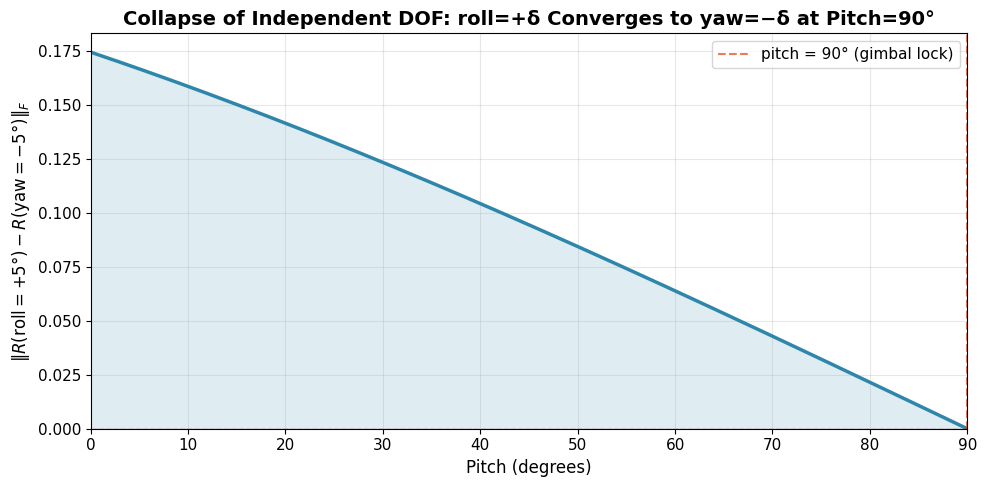

At pitch= 0°: ||R(roll=+5°) - R(yaw=-5°)|| = 0.1744  (very different: 2 independent DOF)
At pitch=90°: ||R(roll=+5°) - R(yaw=-5°)|| = 0.000000 (identical: 1 DOF lost = gimbal lock)


In [12]:
# Sweep pitch from 0 to 90° and show the effective DOF collapsing.
# We measure ||R(roll=+δ) - R(yaw=-δ)||: these two rotations should be identical
# at pitch=90° (same roll-yaw difference), and increasingly different at pitch=0°.

pitch_range = np.linspace(0, np.pi/2, 200)
delta = np.radians(5)

distinguishability = []
for p in pitch_range:
    R_roll = euler_to_rotation_matrix(roll=delta, pitch=p, yaw=0)
    R_yaw_neg = euler_to_rotation_matrix(roll=0, pitch=p, yaw=-delta)  # negative yaw
    distinguishability.append(np.linalg.norm(R_roll - R_yaw_neg, 'fro'))

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(np.degrees(pitch_range), distinguishability, color=C_BODY, lw=2.5)
ax.axhline(y=0, color='red', linestyle='--', alpha=0.5, lw=1)
ax.axvline(x=90, color=C_ACCENT, linestyle='--', alpha=0.7, lw=1.5, label='pitch = 90° (gimbal lock)')
ax.fill_between(np.degrees(pitch_range), distinguishability, alpha=0.15, color=C_BODY)
ax.set_xlabel('Pitch (degrees)', fontsize=12)
ax.set_ylabel(r'$\|R(\mathrm{roll}{=}{+}5°) - R(\mathrm{yaw}{=}{-}5°)\|_F$', fontsize=12)
ax.set_title('Collapse of Independent DOF: roll=+δ Converges to yaw=−δ at Pitch=90°', fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
ax.set_xlim(0, 90)
ax.set_ylim(bottom=0)
plt.tight_layout()
plt.show()

print(f'At pitch= 0°: ||R(roll=+5°) - R(yaw=-5°)|| = {distinguishability[0]:.4f}  (very different: 2 independent DOF)')
print(f'At pitch=90°: ||R(roll=+5°) - R(yaw=-5°)|| = {distinguishability[-1]:.6f} (identical: 1 DOF lost = gimbal lock)')

### The rocket never locks; only the coordinates do

Two different things share the word "yaw", and separating them is what makes gimbal lock stop being mysterious.

**A body-frame maneuver.** "Turn the nose 5° to the left" means: rotate about body Z by 5°, from whatever attitude you happen to be in. In matrix form that is a post-multiplication,

$$R_\text{new} = R \cdot R_z(5^\circ)$$

Post-multiplying applies a rotation in the **body** frame; pre-multiplying ($R_z(5^\circ) \cdot R$) applies it in the **world** frame. A body-frame maneuver is well defined at every attitude, without exception. It is what a gimballed engine or an RCS thruster physically does, and the body rates a gyro measures, $\boldsymbol{\omega} = (p, q, r)$, are rates of exactly this kind. They never degenerate.

**The Euler coordinate $\psi$.** One of three numbers naming an attitude in the ZYX chart, defined as a turn about world Z. It is an address, not a motion.

A single body-frame rotation generally changes **all three** Euler coordinates at once. Near pitch $= \pm 90^\circ$, an ordinary tiny body rotation demands an enormous change in those coordinates, and that is what "the parameterization breaks" means in practice. Below, the rocket rotates in identical 1° steps about its own body Z axis the entire way. The motion is uniform; the numbers describing it are not.


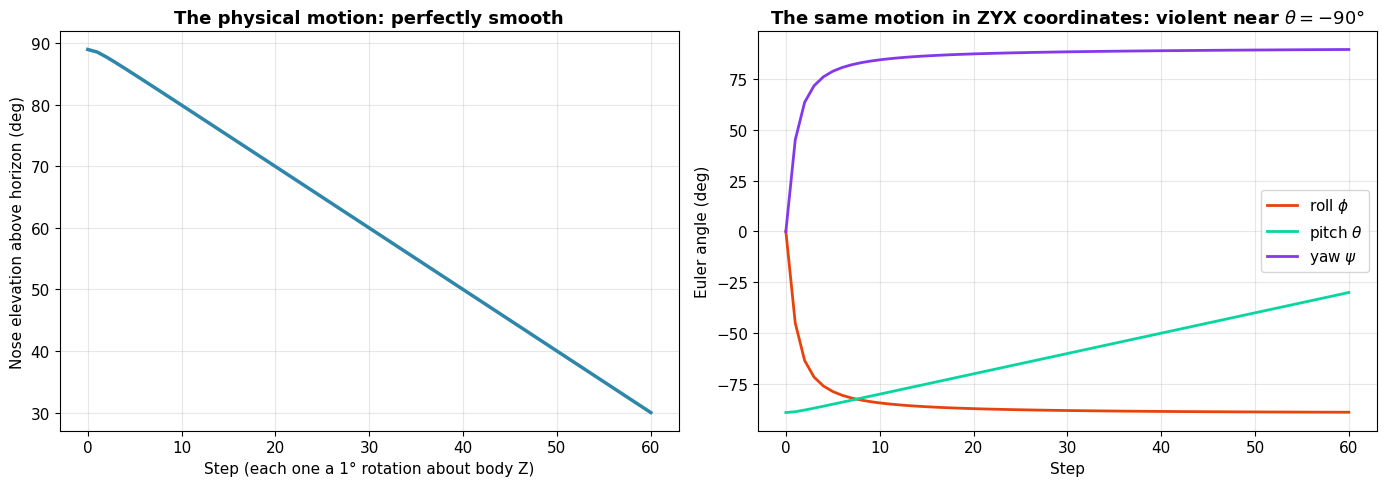

Step 0 -> 1, a single 1.00° rotation about the body Z axis:
    nose elevation:   89.00 ->   88.59 deg   (moves 0.41 deg)
    Euler yaw:         0.00 ->   45.00 deg   (moves 45.00 deg)
    Euler roll:        0.00 ->  -45.00 deg   (moves 45.00 deg)

The commanded maneuver is the same 1° at every step, and the rocket does not
care where it is pointing. Only the coordinates blow up, and they blow up
worst where the roll and yaw axes are most nearly aligned.


In [13]:
# Rotate the rocket in equal 1-degree steps about its OWN body Z axis, starting
# just 1 degree away from nose-up, and watch what the ZYX coordinates have to do
# to keep up.

def rotation_matrix_to_euler(R):
    """Rotation matrix -> ZYX Euler angles (roll, pitch, yaw), in radians."""
    pitch = -np.arcsin(np.clip(R[2, 0], -1.0, 1.0))
    yaw = np.arctan2(R[1, 0], R[0, 0])
    roll = np.arctan2(R[2, 1], R[2, 2])
    return roll, pitch, yaw


step_size = np.radians(1.0)
n_steps = 60

R_current = euler_to_rotation_matrix(roll=0, pitch=np.radians(-89), yaw=0)

roll_history = []
pitch_history = []
yaw_history = []
nose_elevation_history = []

for step in range(n_steps + 1):
    roll, pitch, yaw = rotation_matrix_to_euler(R_current)
    roll_history.append(np.degrees(roll))
    pitch_history.append(np.degrees(pitch))
    yaw_history.append(np.degrees(yaw))

    nose_world = R_current @ np.array([1.0, 0.0, 0.0])
    nose_elevation_history.append(np.degrees(np.arcsin(np.clip(nose_world[2], -1.0, 1.0))))

    # Post-multiply: this applies the rotation in the BODY frame
    R_current = R_current @ rot_z(step_size)

steps = np.arange(n_steps + 1)

fig, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(14, 5))

ax_left.plot(steps, nose_elevation_history, color=C_BODY, lw=2.5)
ax_left.set_xlabel('Step (each one a 1° rotation about body Z)', fontsize=11)
ax_left.set_ylabel('Nose elevation above horizon (deg)', fontsize=11)
ax_left.set_title('The physical motion: perfectly smooth', fontsize=13, fontweight='bold')

ax_right.plot(steps, roll_history, color=C_ACCENT, lw=2.0, label=r'roll $\phi$')
ax_right.plot(steps, pitch_history, color=C_GREEN, lw=2.0, label=r'pitch $\theta$')
ax_right.plot(steps, yaw_history, color=C_ACCENT2, lw=2.0, label=r'yaw $\psi$')
ax_right.set_xlabel('Step', fontsize=11)
ax_right.set_ylabel('Euler angle (deg)', fontsize=11)
ax_right.set_title(r'The same motion in ZYX coordinates: violent near $\theta = -90\degree$',
                   fontsize=13, fontweight='bold')
ax_right.legend(fontsize=11)

plt.tight_layout()
plt.show()

print('Step 0 -> 1, a single 1.00° rotation about the body Z axis:')
print(f'    nose elevation: {nose_elevation_history[0]:7.2f} -> {nose_elevation_history[1]:7.2f} deg'
      f'   (moves {abs(nose_elevation_history[1] - nose_elevation_history[0]):.2f} deg)')
print(f'    Euler yaw:      {yaw_history[0]:7.2f} -> {yaw_history[1]:7.2f} deg'
      f'   (moves {abs(yaw_history[1] - yaw_history[0]):.2f} deg)')
print(f'    Euler roll:     {roll_history[0]:7.2f} -> {roll_history[1]:7.2f} deg'
      f'   (moves {abs(roll_history[1] - roll_history[0]):.2f} deg)')
print()
print('The commanded maneuver is the same 1° at every step, and the rocket does not')
print('care where it is pointing. Only the coordinates blow up, and they blow up')
print('worst where the roll and yaw axes are most nearly aligned.')


### The Intuition, Summarized

1. A physical body can rotate to any orientation at any time, and can rotate about any axis it likes from any attitude. Nothing prevents this, ever. Gimbal lock is not something that happens to the rocket.

2. To _track_ and _control_ orientation we need coordinates. Euler angles are one choice: three numbers applied as three single-axis rotations in a fixed nested order, yaw outermost and roll innermost.

3. That nesting is the whole problem. The roll axis is carried around by pitch, and at pitch $= \pm 90^\circ$ it lands on top of the yaw axis. Two of the three knobs then point along the same line and the third direction is unreachable. The angle between those two axes is $90^\circ - |\theta|$, so the conditioning degrades continuously as the rocket pitches up.

4. Any decomposition of a 3-DOF rotation into three sequential single-axis turns has this defect somewhere; it is not a flaw in ZYX specifically. Quaternions avoid it by not decomposing rotation into a sequence at all.

5. **For Icarus, this is immediately relevant**: the rocket sits vertical on the pad, which is pitch $= -90^\circ$ in our convention, and it comes back to vertical at touchdown. Both are gimbal lock. An Euler-angle attitude representation would be singular at liftoff and at landing, exactly when fine attitude control against wind gusts matters most. This is the practical engineering reason rockets use quaternions.


---
## 4. Quaternions: The Fix

A **unit quaternion** is a 4-vector $q = [w, x, y, z]$ with $\|q\| = 1$.

**Axis-angle interpretation:** To rotate by angle $\theta$ about unit axis $\hat{n}$:

$$q = \left[\cos\frac{\theta}{2}, \; \sin\frac{\theta}{2} \cdot \hat{n} \right]$$

**Rotation formula:** Given a vector $v$, treat it as a pure quaternion $[0, v]$, then:

$$v' = q \otimes [0, v] \otimes q^*$$

where $\otimes$ denotes **quaternion multiplication** (the Hamilton product), and $q^* = [w, -x, -y, -z]$ is the quaternion conjugate. 

Why quaternions win:
- **No singularities:** every orientation has a unique quaternion (up to sign)
- **Smooth interpolation:** SLERP gives the shortest path
- **Cheap composition:** quaternion multiply is 16 multiplies + 12 adds
- **Easy normalization:** just divide by the norm

In [19]:
# Quaternion basics: rotate a vector

# Rotate [1, 0, 0] by 90 degrees about Z axis
v = np.array([1.0, 0.0, 0.0])
angle = np.pi/ 2
axis = np.array([0.0, 0.0, 1.0])

# Method 1: rotation matrix
R = rot_z(angle)
v_mat =  R @ v

# Method 2: quaternion
q = quat_from_axis_angle(axis, angle)
v_quat = quat_rotate_vector(q, v)

print('Rotating [1, 0, 0] by 90° about Z axis:')
print(f'    Rotation matrix: {v_mat}')
print(f'    Quaternion:       {v_quat}')
print(f'    Difference:       {np.linalg.norm(v_mat - v_quat):.2e}')
print()
print(f'Quaternion used: q = [{q[0]:.4f}, {q[1]:.4f}, {q[2]:.4f}, {q[3]:.4f}]')
print('  = [cos(45), sin(45) * (0, 0, 1)]')
print('  = [cos(θ/2), sin(θ/2) * axis]')
print(f'  ||q|| = {np.linalg.norm(q):.4f} (unit quaternion)')

Rotating [1, 0, 0] by 90° about Z axis:
    Rotation matrix: [6.123234e-17 1.000000e+00 0.000000e+00]
    Quaternion:       [2.22044605e-16 1.00000000e+00 0.00000000e+00]
    Difference:       1.61e-16

Quaternion used: q = [0.7071, 0.0000, 0.0000, 0.7071]
  = [cos(45), sin(45) * (0, 0, 1)]
  = [cos(θ/2), sin(θ/2) * axis]
  ||q|| = 1.0000 (unit quaternion)


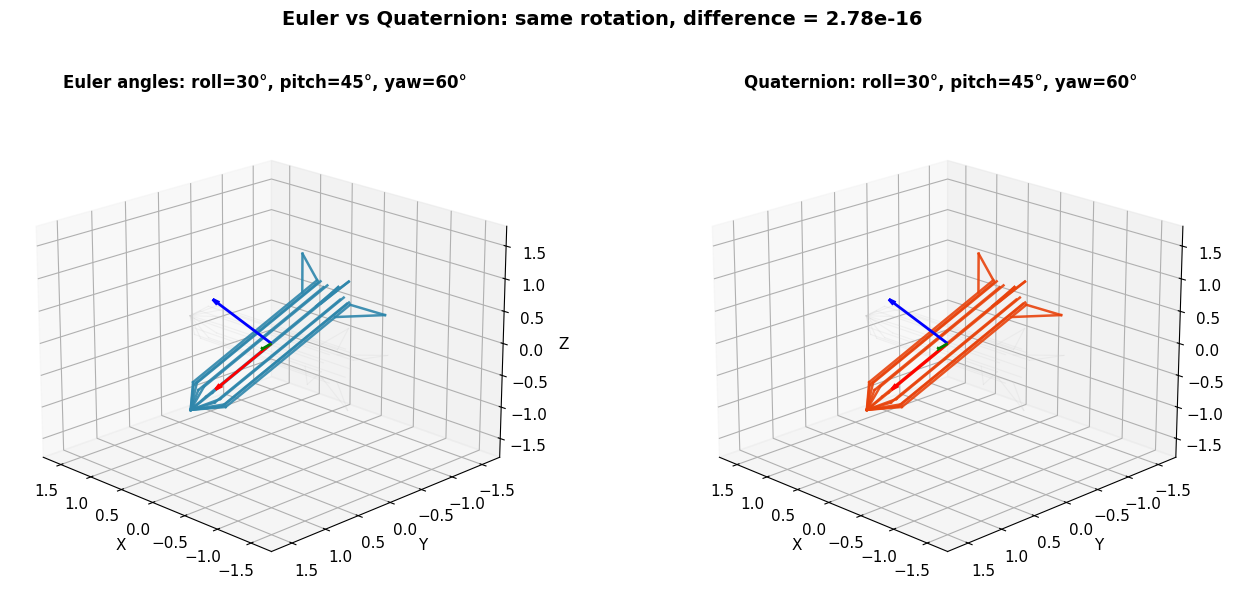

In [20]:
# Visual: same rocket, rotated by quaternion vs Euler angles (they match)

roll, pitch, yaw = np.radians(30), np.radians(45), np.radians(60)

# Euler angle rotation matrix
R_euler = euler_to_rotation_matrix(roll, pitch, yaw)

# Quaternion rotation matrix
q = quat_from_euler(roll, pitch, yaw)
R_quat = quat_to_rotation_matrix(q)

fig = plt.figure(figsize=(14, 6))

ax1 = fig.add_subplot(121, projection='3d')
draw_body_3d(ax1, rocket, np.eye(3), color=C_GHOST, alpha=0.2, linewidth=0.8)
draw_body_3d(ax1, rocket, R_euler, color=C_BODY, alpha=0.9, linewidth=1.8)
draw_axes_3d(ax1, R_euler, length=0.9)
set_equal_3d_axes(ax1, radius=1.8)
ax1.set_title('Euler angles: roll=30°, pitch=45°, yaw=60°', fontsize=12, fontweight='bold')
ax1.view_init(elev=20, azim=135)

ax2 = fig.add_subplot(122, projection='3d')
draw_body_3d(ax2, rocket, np.eye(3), color=C_GHOST, alpha=0.2, linewidth=0.8)
draw_body_3d(ax2, rocket, R_quat, color=C_ACCENT, alpha=0.9, linewidth=1.8)
draw_axes_3d(ax2, R_quat, length=0.9)
set_equal_3d_axes(ax2, radius=1.8)
ax2.set_title('Quaternion: roll=30°, pitch=45°, yaw=60°', fontsize=12, fontweight='bold')
ax2.view_init(elev=20, azim=135)

diff = np.linalg.norm(R_euler - R_quat, 'fro')
fig.suptitle(f'Euler vs Quaternion: same rotation, difference = {diff:.2e}', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Euler Angles vs Quaternions

| Property | Euler Angles | Quaternions |
|:-------- |:-------------|:------------|
| **Parameters** | 3 (roll, pitch, yaw) | 4 (w, x, y, z) with unit constraint |
| **Singularities** | Yes (gimbal lock at pitch = +/- 90) | None |
| **Interpolation** | Linear interp is janky, can go through singularity | SLERP: smooth, shortest path, constant speed |
| **Composition** | Matrix multiply (27 mults) | Quaternion multiply (16 mults) |
| **Intuition** | Easy (roll/pitch/yaw) | Hard (4D hypersphere) |
| **Uniqueness** | Infinite representations at gimbal lock | Double cover: q and -q are the same rotation |
| **Normalization** | Re-orthogonalize 3x3 matrix (SVD) | Divide by norm (trivial) |

## Quaternion Algebra: How Multiplication Works

We've been using `quat_multiply` as a black box. Let's open it. A quaternion is $q = w + xi + yj + zk$ where $i, j, k$ are imaginary units satisfying:

$$i^2 = j^2 = k^2 = ijk = -1$$

This gives the cyclic rules: $ij = k$, $jk = i$, $ki = j$ (and $ji = -k$, etc.; non-commutative).

Multiplying two quaternions $q_1 q_2$ is just distributing and applying these rules. The scaler-vector form makes it cleaner: writing $q = [s, \mathbf{v}]$ where $s$ is the scaler part and $\mathbf{v} = [x, y, z]$:

$$q_1 q_2 = [s_1 s_2 - \mathbf{v}_1 \cdot \mathbf{v}_2, \; s_1 \mathbf{v}_2 + s_2 \mathbf{v}_1 \times \mathbf{v}_2]$$

The dot product in the scaler part and the cross product in the vector part; that's why quaternions encode rotations so naturally. 

## The Double Cover: q and -q

Here's a subtlety that can bite us when building attitude controllers. Quaternions $q$ and $-q$ represent the **exact same rotation**:

In [21]:
# q and -q produce identical rotations


**Why this matters for Icarus**: When computing attitude error for a controller (e.g., $q_{\text{error}} = q_{\text{desired}}^* \otimes q_{\text{current}}$), we need to check whether $q_{\text{error}}$ or $-q_{\text{error}}$ gives the **shorter rotation path**. 

The convention: if $q_{\text{error}}[0] < 0$, negate it. Without this check, our controller might command a 350 degree rotation instead of a 10 degree rotation. 

---
## 5. Euler <--> Quaternion Conversion

We can convert between Euler angles and quaternions using `quat_from_euler` and `quat_to_euler`. They should agree everywhere... except near gimbal lock. 

In [22]:
# Test round-trip conversion from random orientations

In [23]:
# Now test NEAR gimbal lock; sweep pitch and measure conversion error between Euler and quaternion representations

---
### 6. SLERP: Smooth Interpolation

We can now represent any orientation as a quaternion. But in practice, we often need to **smoothly transition** between two orientations; e.g., the rocket is tilted at 30° and we want it vertical. We can't teleport; we need a path of intermediate orientations for the controller to track.

The naïve approach: linearly interpolate each Euler angle from start to end; works far from gimbal lock, but produces erratic paths and variable rotation speed near singularities. The problem is that Euler angles don't parameterize rotation space uniformly. 

**SLERP (Spherical Linear Interpolation)** interpolates directly on the quaternion unit sphere. Since quaternions live on a sphere, the "straight line" between two orientations is a great arc, which gives us the **shortest rotation path** at **constant angular velocity**. No singularities, no detours, no speed variation. 

For Icarus, we'd use SLERP when generating reference attitude trajectories: "at t=0 the rocket is at orientation A, at t=10 I want orientation B - give me smooth intermediate attitudes for each timestep." Our guidance module SLERPs between waypoint orientations, and the attitude controller tracks that smooth reference. 

**Method 1: Linear Euler Interpolation:** Linearly interpolate roll, pitch, yaw. Seems natural, but near gimbal lock it takes wild detours and produces jerky motion. 

**Method 2: SLERP:** Walk along the great arc on the uqaternion unit sphere. Shortest path, constant angular velocity, no singularities. 

In [24]:
# Define start and end orientations that go through gimbal lock
# A: slighltly pitched up, rolled left
# B: slighltly pitched up, rolled right and yawwed (path goes through gimbal lock)

# Method 1: Linear Euler interpolation

# Method 2: SLERP

In [25]:
# Static comprison: show snapshots at t = 0, 0.33, 0.67, 1.0

In [26]:
# Animate both side by side

In [27]:
# Quantify: angular velocity should be CONSTANT for SLERP
# Measure the rotation angle between consecutive frames

---
## 7. Quaternion Kinematics: The Bridge to Dynamics